# 1. INTRODUCTION

This is the Final Project for completion of the TripleTen Data Science Bootcamp.

The purpose of this project is to demonstrate skills in developing a predictive model that can be applied to a real-world business case study. The case concerns a steel plant called **Steelproof**, which needs to optimize its processes and eventually reduce costs, particularly those related to electricity. There are limitations to what can be modeled using the data provided, and no additional data or information beyond what is included in this notebook is available. To complete the project, we will provide a detailed explanation of the process described by **Steelproof**, analyze the available data, develop a project plan, and discuss potential applications of the model. We will also discuss the project's limitations and possible future extensions that could bring it closer to **Steelproof's** objectives.

## 1.1 Industry – Steelproof

The **Steelproof** steel plant seeks to **optimize its production costs** during a stage of **steel processing** known as **secondary refining in a ladle furnace**.

Our objective is to **develop a model that can predict the metal's temperature**, helping the plant make more efficient and sustainable decisions in its industrial processes.

## 1.2 About Secondary Steel Refining

According to Alvarenga (2023), secondary steel refining follows primary refining. During the first stage, steel is converted to liquid steel in a highly oxidizing environment, resulting in oxygen levels above the acceptable limits for most finished steel products. Secondary refining was therefore developed using various deoxidation techniques, while also aiming to optimize steel processing and improve control over the final product.

According to Rizzo (2006), as cited by Alvarenga (2023), the main objectives of secondary refining are:

1. Reducing steel treatment time to increase production and productivity and lower the plant's operating costs;
2. Providing greater operational flexibility and optimizing production flow from the melting furnace through steel casting;
3. Controlling liquid steel temperature through electrical and chemical heating;
4. Fine-tuning the chemical composition of the steel;
5. Increasing steel cleanliness;
6. Controlling the microstructure and/or macrostructure of solidified products.

To meet these objectives, equipment and processes were developed for applications such as chemical heating, vacuum degassing, remelting solidified products, and the use of the ladle furnace (Rizzo, 2006).

## 1.3 Example Stages of Secondary Refining at the Steelproof Steel Plant

According to Rizzo (2006):

1. The ladle containing liquid steel from primary refining is transported to the ladle furnace.
2. Ferroalloys or pure metals are added to adjust the steel's chemical composition based on a sample taken at the end of primary refining.
3. Deoxidation using silicon and/or aluminum may be carried out if necessary.
4. Lime or synthetic slag is added to adjust the amount of slag in the ladle, preventing electrode exposure during heating. This prevents the electric arc produced by the electrode from damaging the ladle furnace or creating conditions favorable to steel reoxidation. An exposed graphite electrode also wears out rapidly and becomes inefficient because not all of its heat is transferred to the steel.
5. The steel is purged with an inert gas, which stirs the liquid steel. This promotes homogenization by helping the chemical composition stabilize throughout the melt and making the temperature more uniform. Without stirring, some additions may remain concentrated near the top. By definition, the gas is inert and does not react with the steel; it also produces some degassing and is eventually removed through dedicated channels in the ladle.
6. The furnace is turned on for the first heating cycle, reversing the tendency for temperature to fall after the earlier additions. The heating period is typically 10–15 minutes and normally does not exceed that range, to avoid temperatures high enough to damage the ladle. However, slag removal causes a greater temperature decrease and may require longer heating.
7. After these steps, a steel sample is taken to check temperature and chemical composition. Deoxidation may be performed at this point if it has not already taken place.
8. The second heating cycle is then performed based on the desired final temperature. The temperature increase is steady but depends on the power applied, potentially reaching 3.5–6°C per minute.
9. If a minor chemical-composition adjustment is needed, heating may be interrupted, or additions may be made while the furnace is operating, depending on the element being adjusted.
10. To complete the process, a final sample is taken; chemical composition and temperature are analyzed, and the steel is released for casting or further secondary-refining treatment in other equipment.
11. If further adjustments are required, additions may be made again, repeating the heating, inert-gas purging, and sampling cycle.

**Note:** These stages form a hypothetical example for the Steelproof steel plant and assume electrically powered ladle-furnace heating through graphite electrodes positioned in the ladle cover. The example also assumes that the steel is stirred through the introduction of inert gases. Alternative processes use chemical heating, electromagnetic stirring, and other variations. This summary should not be taken as a comprehensive description of every possible secondary-refining process.

# TECHNICAL OBJECTIVE OF THE PROJECT

Our objective is to train a predictive regression model to estimate the steel temperature inside the ladle furnace using previous temperature measurements, material additions, inert-gas stirring/purging, and other data. Specifically, we will define a training interval for our model with the following characteristics:

- It begins with a temperature measurement $T_{1}$.
- It contains at least **one** heating cycle, but it may include more.
- It may or may not include additions of bulk or wire materials during the interval.
- It ends with a temperature measurement $T_{2}$.

Our goal is to train a model that predicts the final temperature $T_{2}$ based on information available before that measurement.

We can define the model's objective as follows:

$\hat{T} = f(X)$

Here, $\hat{T}$ is the temperature predicted by the model, and $X$ represents the data available about the interval preceding the temperature measurement, such as:

- Timing information about temperature measurement $T_{1}$ and its temporal relationship with $T_{2}$.
- Information about the heating cycles occurring during the interval.
- Timing information about those heating cycles.
- Information on bulk and wire material additions, including their quantities and timestamps.
- Other features derived from the available data.

# POTENTIAL BUSINESS APPLICATIONS

The primary practical application of the proposed model is as a "virtual temperature sensor." Such a virtual sensor could be used after a steel-heating cycle, taking into account all information collected since the last temperature measurement to predict the steel's current temperature. Ideally, a model with reliable performance would produce estimates sufficiently close to actual measurements that, within an acceptable margin, the plant could optimize its processes and avoid heating cycles that might overheat the steel or damage the ladle furnace. Without predictive models, heating and measurement decisions are made by operators based on various calculations and established practices. If its performance proves adequate, the model could provide a more reliable technical reference. Avoiding unnecessary heating cycles could consequently reduce electricity costs, including those associated with excessively long heating cycles or repeated heating when a previous cycle failed to achieve the required steel temperature.

Even if a direct measurement is still taken after heating, the model could serve as a reference that flags unexpected conditions before the measurement is performed. The same virtual sensor might also modestly reduce costs. If the model proves reliable in predicting temperature—even if only under specific conditions—it could eliminate the need for certain direct measurements. Measuring steel temperature involves costs related to the wear or consumption of measurement materials, so reducing the number of measurements might be beneficial to **Steelproof**, even if the savings are indirect. As we will see, many direct temperature measurements are taken in succession, and reducing these measurements is one possible avenue for optimization.

# Technical Set-up of Notebook

This section sets up the technical structure of this notebook for presenting our initial pre-analysis and work plan.

### Importing Libraries

In [1]:
import pandas as pd
from pathlib import Path
from matplotlib import pyplot as plt
import seaborn as sns
import numpy as np
import random

### Setting the Seaborn Plot Theme

In [2]:
sns.set_theme("notebook")

### Defining the Data Location

In [3]:
# Folder containing the datasets
# This variable makes it easier to move the notebook between my local
# environment and the bootcamp environment
data_location = Path("../../data/final_steel_en/")

### Defining a Function to Standardize Column Names

In [4]:
## helper function -> snake_case
# This function standardizes column names using snake_case
def snake_case_columns(df:pd.DataFrame):
    df.columns = (
        df.columns.str.lower()
        .str.strip()
        .str.replace("-","_")
        .str.replace(" ","_")
    )
    return df

### Random State

In [5]:
# This variable keeps the notebook random states consistent

random_state=12345

### LOADING THE DATA

The datasets will be loaded and their column names converted to `snake_case` (lowercase words separated by underscores).

In [6]:
# Electrode data
data_arc_en_raw = pd.read_csv(data_location / "data_arc_en.csv",parse_dates=["Arc heating start", 'Arc heating end'])
data_arc_en = data_arc_en_raw.copy()
data_arc_en = snake_case_columns(data_arc_en)

#
data_bulk_en_raw = pd.read_csv(data_location / "data_bulk_en.csv")
data_bulk_en = data_bulk_en_raw.copy()
data_bulk_en = snake_case_columns(data_bulk_en)

data_bulk_time_en_raw = pd.read_csv(data_location / "data_bulk_time_en.csv",parse_dates=[x for x in range(1,16,1)])
data_bulk_time_en = data_bulk_time_en_raw.copy()
data_bulk_time_en = snake_case_columns(data_bulk_time_en)

data_gas_en_raw = pd.read_csv(data_location / "data_gas_en.csv")
data_gas_en = data_gas_en_raw.copy()
data_gas_en = snake_case_columns(data_gas_en)

data_temp_en_raw = pd.read_csv(data_location / "data_temp_en.csv", parse_dates=['Sampling time'])
data_temp_en = data_temp_en_raw.copy()
data_temp_en = snake_case_columns(data_temp_en)

data_wire_en_raw = pd.read_csv(data_location / "data_wire_en.csv")
data_wire_en = data_wire_en_raw.copy()
data_wire_en = snake_case_columns(data_wire_en)

data_wire_time_en_raw = pd.read_csv(data_location / "data_wire_time_en.csv", parse_dates=[x for x in range(1,10,1)])
data_wire_time_en = data_wire_time_en_raw.copy()
data_wire_time_en = snake_case_columns(data_wire_time_en)

# DATA DESCRIPTION

## Electrode Data (`data_arc_en.csv`)

This dataset contains information about heating cycles performed using graphite electrodes. Each row represents one heating cycle belonging to a secondary-refining batch identified by the `key` column.

### Data Examples

In [7]:
data_arc_en.head()

,key,arc_heating_start,arc_heating_end,active_power,reactive_power
0,1,2019-05-03 11:02:14,2019-05-03 11:06:02,0.976059,0.687084
1,1,2019-05-03 11:07:28,2019-05-03 11:10:33,0.805607,0.520285
2,1,2019-05-03 11:11:44,2019-05-03 11:14:36,0.744363,0.498805
3,1,2019-05-03 11:18:14,2019-05-03 11:24:19,1.659363,1.062669
4,1,2019-05-03 11:26:09,2019-05-03 11:28:37,0.692755,0.414397


In [8]:
data_arc_en.sample(n=5,random_state=random_state)

,key,arc_heating_start,arc_heating_end,active_power,reactive_power
4557,984,2019-06-08 12:00:37,2019-06-08 12:02:18,0.392892,0.301553
5274,1144,2019-06-14 02:02:26,2019-06-14 02:04:31,0.572077,0.380522
1668,359,2019-05-17 01:03:38,2019-05-17 01:07:32,0.963486,0.659530
10682,2323,2019-07-30 18:57:21,2019-07-30 19:01:13,0.927218,0.762333
4321,927,2019-06-06 12:45:46,2019-06-06 12:50:09,1.122471,0.807470


### Data Analysis

In [9]:
data_arc_en.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 14876 entries, 0 to 14875
Data columns (total 5 columns):
 #   Column             Non-Null Count  Dtype         
---  ------             --------------  -----         
 0   key                14876 non-null  int64         
 1   arc_heating_start  14876 non-null  datetime64[ns]
 2   arc_heating_end    14876 non-null  datetime64[ns]
 3   active_power       14876 non-null  float64       
 4   reactive_power     14876 non-null  float64       
dtypes: datetime64[ns](2), float64(2), int64(1)
memory usage: 581.2 KB


None of the columns have missing values.

The electrode dataset contains 14,876 rows, representing 14,876 heating cycles.

It also contains five columns:
- `key` — an identifier corresponding to an entire secondary-refining **batch**, from the introduction of liquid steel into the ladle furnace until it is released for casting.
- `arc_heating_start` — the timestamp when a heating cycle begins. There can be several rows with different timestamps for the same `key`, since each secondary-refining batch may have multiple heating cycles.
- `arc_heating_end` — the timestamp when a heating cycle ends.
- `active_power` — a variable representing active power, directly related to electrical energy use.
- `reactive_power` — a variable representing reactive power, indirectly related to electrical energy use.

#### NOTE: Units of measurement

We do not have the units of measurement or detailed descriptions of `active_power` and `reactive_power`. Therefore, we cannot establish whether these variables represent total power consumed in each heating cycle, average power throughout the cycle, constant power settings used to control ladle-furnace heating, or even peak power during the cycle. Neither Steelproof's project description nor research on the industry provided enough information to clarify these variables. We also could not establish whether power typically varies during a heating cycle, whether such variation is measured, or how those measurements are recorded. As will be discussed later, this prevents us from defining an appropriate method to aggregate power values from different heating cycles into a secondary-refining batch (the calculation would differ depending on whether the values were totals, averages, machine settings, or peaks).

Although we can use descriptive features from these columns, as well as additional engineered features, when training our model, we cannot draw strong conclusions from their descriptive statistics about energy expenditure or directly incorporate them into a formula for electrical energy consumption.

This does not necessarily mean that the values must be ignored or excluded from model training. Data scientists are often given masked variables that must be used without full knowledge of their original meaning or units. We will need to take care not to misuse these values, but we can still use them in training because our regression model will learn relationships and patterns among these and other inputs to predict steel temperature.

In [10]:
data_arc_en.describe(include='all',datetime_is_numeric=True)

,key,arc_heating_start,arc_heating_end,active_power,reactive_power
count,14876.000000,14876,14876,14876.000000,14876.000000
mean,1615.220422,2019-07-02 16:15:28.218203904,2019-07-02 16:18:19.889150208,0.670441,0.452592
min,1.000000,2019-05-03 11:02:14,2019-05-03 11:06:02,0.030002,-715.504924
25%,806.000000,2019-06-02 07:01:09.249999872,2019-06-02 07:04:21,0.395297,0.290991
50%,1617.000000,2019-06-30 09:57:14.500000,2019-06-30 10:01:01,0.555517,0.415962
75%,2429.000000,2019-08-03 13:04:47.750000128,2019-08-03 13:09:14,0.857034,0.637371
max,3241.000000,2019-09-01 04:34:47,2019-09-01 04:36:08,3.731596,2.676388
std,934.571502,NaN,NaN,0.408159,5.878702


The `key` column contains identifiers ranging from 1 to 3,241. Its other descriptive statistics are not useful for our purposes. We might convert the column to strings because these identifiers are labels for secondary-refining batches rather than numerical quantities used in calculations. We will make that decision during model development, when we know whether there is any advantage to retaining the integer (`int64`) representation.

We also notice that the descriptive statistics for `arc_heating_start` show a frequency of 2 for the value designated as *top*. This means that at least one timestamp is duplicated and should be investigated.

The `active_power` column does not appear to have problems, but we cannot interpret its descriptive statistics very far because, as noted earlier, we do not know exactly how it was constructed. Its standard deviation (`std`) is approximately 0.41, with a mean of 0.67.

The `reactive_power` column has a much larger standard deviation of 5.88 and a mean of 0.45. However, both statistics may be strongly affected by extreme values, such as the negative minimum of approximately −715.50.

### Analyzing the Number of Heating Cycles per Secondary-Refining Batch

In [11]:
heating_cycles_per_key = data_arc_en.groupby("key").size().rename("cycles")

print(f"Average heating cycles per secondary-refining batch: {heating_cycles_per_key.mean():.2f}")
print(f"Minimum heating cycles per secondary-refining batch: {heating_cycles_per_key.min():.2f}")
print(f"Maximum heating cycles per secondary-refining batch: {heating_cycles_per_key.max():.2f}")


Average heating cycles per secondary-refining batch: 4.63
Minimum heating cycles per secondary-refining batch: 1.00
Maximum heating cycles per secondary-refining batch: 16.00


The dataset has an average of 4.63 heating cycles per secondary-refining batch, with a minimum of one and a maximum of 16 cycles.

Distribution and Frequency

In [12]:
heating_cycles_frequency_table = (
    heating_cycles_per_key.value_counts()
    .rename_axis("cycles_per_batch", axis=0)
    .reset_index(name="frequency")
)

heating_cycles_frequency_table["relative_frequency"] = heating_cycles_frequency_table["frequency"] / heating_cycles_frequency_table["frequency"].sum()

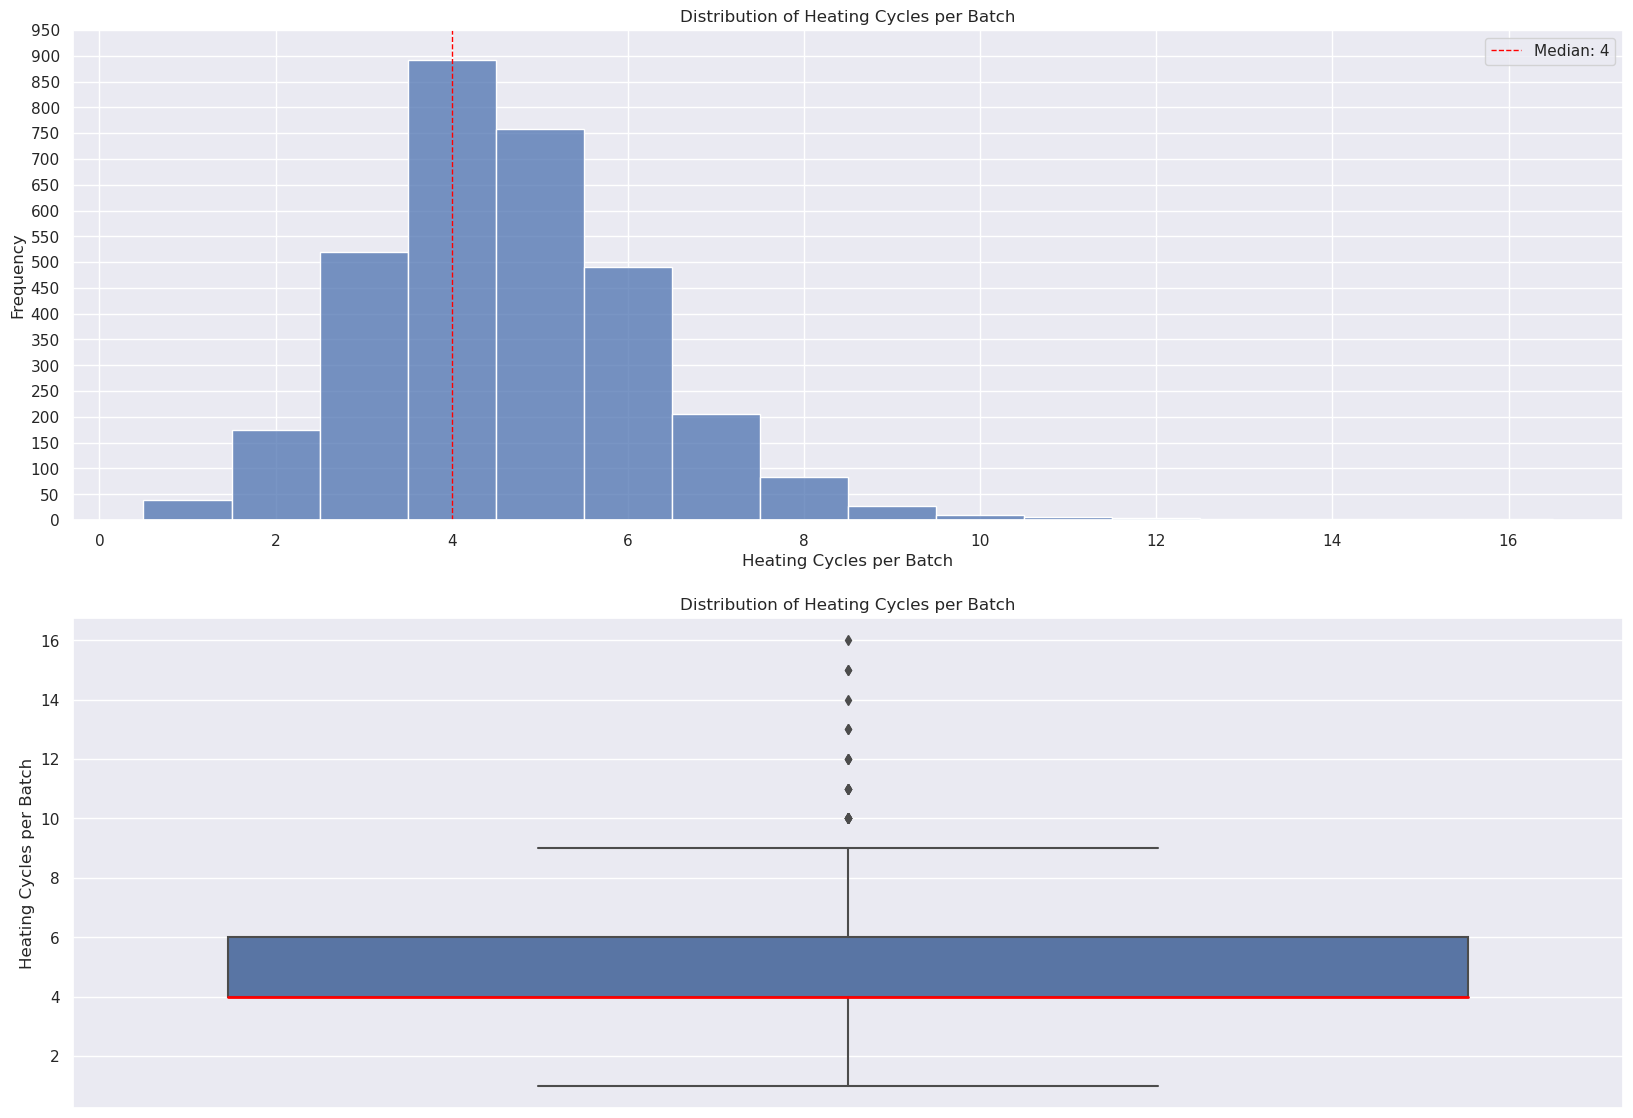

    cycles_per_batch  frequency  relative_frequency
0                  4        892            0.277536
1                  5        759            0.236154
2                  3        520            0.161792
3                  6        490            0.152458
4                  7        205            0.063783
5                  2        174            0.054138
6                  8         84            0.026136
7                  1         39            0.012134
8                  9         28            0.008712
9                 10          9            0.002800
10                11          5            0.001556
11                12          3            0.000933
12                13          2            0.000622
13                15          2            0.000622
14                14          1            0.000311
15                16          1            0.000311


In [13]:
fig, axes = plt.subplots(nrows=2,ncols=1,figsize=(20,14))

sns.histplot(x=heating_cycles_per_key,discrete=True,ax=axes[0])

axes[0].set_title("Distribution of Heating Cycles per Batch")
axes[0].set_xlabel("Heating Cycles per Batch")
axes[0].set_ylabel("Frequency")

stepsize = 50
start, end = axes[0].get_ylim()
axes[0].set_yticks(np.arange(start, end + stepsize, stepsize))

median_val = heating_cycles_per_key.median()

axes[0].axvline(
    x=median_val,
    color="red",
    linestyle="--",
    linewidth=1,
    label=f"Median: {median_val:.0f}"
)
axes[0].legend()

sns.boxplot(y=data_arc_en['key'].value_counts(),ax=axes[1],medianprops={"color": "red", "linewidth": 2})

axes[1].set_title("Distribution of Heating Cycles per Batch")
axes[1].set_ylabel("Heating Cycles per Batch")

plt.show()

print(heating_cycles_frequency_table)

In [14]:
print(f"Relative Frequency of Batches with 4 or 5 Heating Cycles: {heating_cycles_per_key.isin([4,5]).mean()*100:.2f}%")


Relative Frequency of Batches with 4 or 5 Heating Cycles: 51.37%


As shown in the charts above, most batches undergo between two and eight heating cycles, with a particularly high concentration of batches receiving four or five cycles. These account for 51% of all batches, as shown in the frequency table. The median, marked in red, is four cycles per batch.

There are also substantial numbers of batches with two, three, six, seven, or eight heating cycles. In contrast, batches with only one or nine cycles are a small minority, with fewer than 40 batches in each category. Batches with more than ten heating cycles are extremely rare compared with the rest of the dataset; they are barely visible on the chart, with fewer than ten batches for each cycle count.

### In-Depth Analysis of the Timestamp Columns

#### The `arc_heating_start` Column

When loading the data, we used the **`parse_dates`** parameter in **`read_csv`**. This converts the values to the **datetime** type while loading the original DataFrame. However, if the column contains invalid values, the data may instead be loaded as strings (the **object** dtype in the pandas version used for this project). Since `arc_heating_start` was successfully converted to **datetime**, we know that all its values are valid.

Next, we will check for duplicate values. Duplicates are possible if one refining batch is processed while another is also underway. Therefore, identical timestamps associated with different `key` values are acceptable. If we find duplicate timestamps within the same `key`, we will need to investigate.

In [15]:
data_arc_en[data_arc_en.loc[:,"arc_heating_start"].duplicated(keep=False)]

,key,arc_heating_start,arc_heating_end,active_power,reactive_power
4872,1051,2019-06-10 22:02:03,2019-06-10 22:06:02,1.040376,0.635608
4876,1052,2019-06-10 22:02:03,2019-06-10 22:04:31,0.623495,0.508767


The only duplicate `arc_heating_start` value belongs to different batch identifiers, meaning the heating cycles took place in separate secondary-refining processes but began at exactly the same time. This is not a problem, and both records should be retained as they are.

#### The `arc_heating_end` Column

When loading the data, we used the **`parse_dates`** parameter in **`read_csv`**. This converts values to the **datetime** type while loading the original DataFrame, but if the column contains invalid values, the data may instead be loaded as strings (the **object** dtype in the pandas version used for this project). Since `arc_heating_end` was successfully converted to **datetime**, we know that all its values are valid.

#### Analysis of Heating-Cycle Durations

In [16]:
data_arc_en['arc_heating_interval'] = (data_arc_en['arc_heating_end'] - data_arc_en['arc_heating_start']).dt.total_seconds()


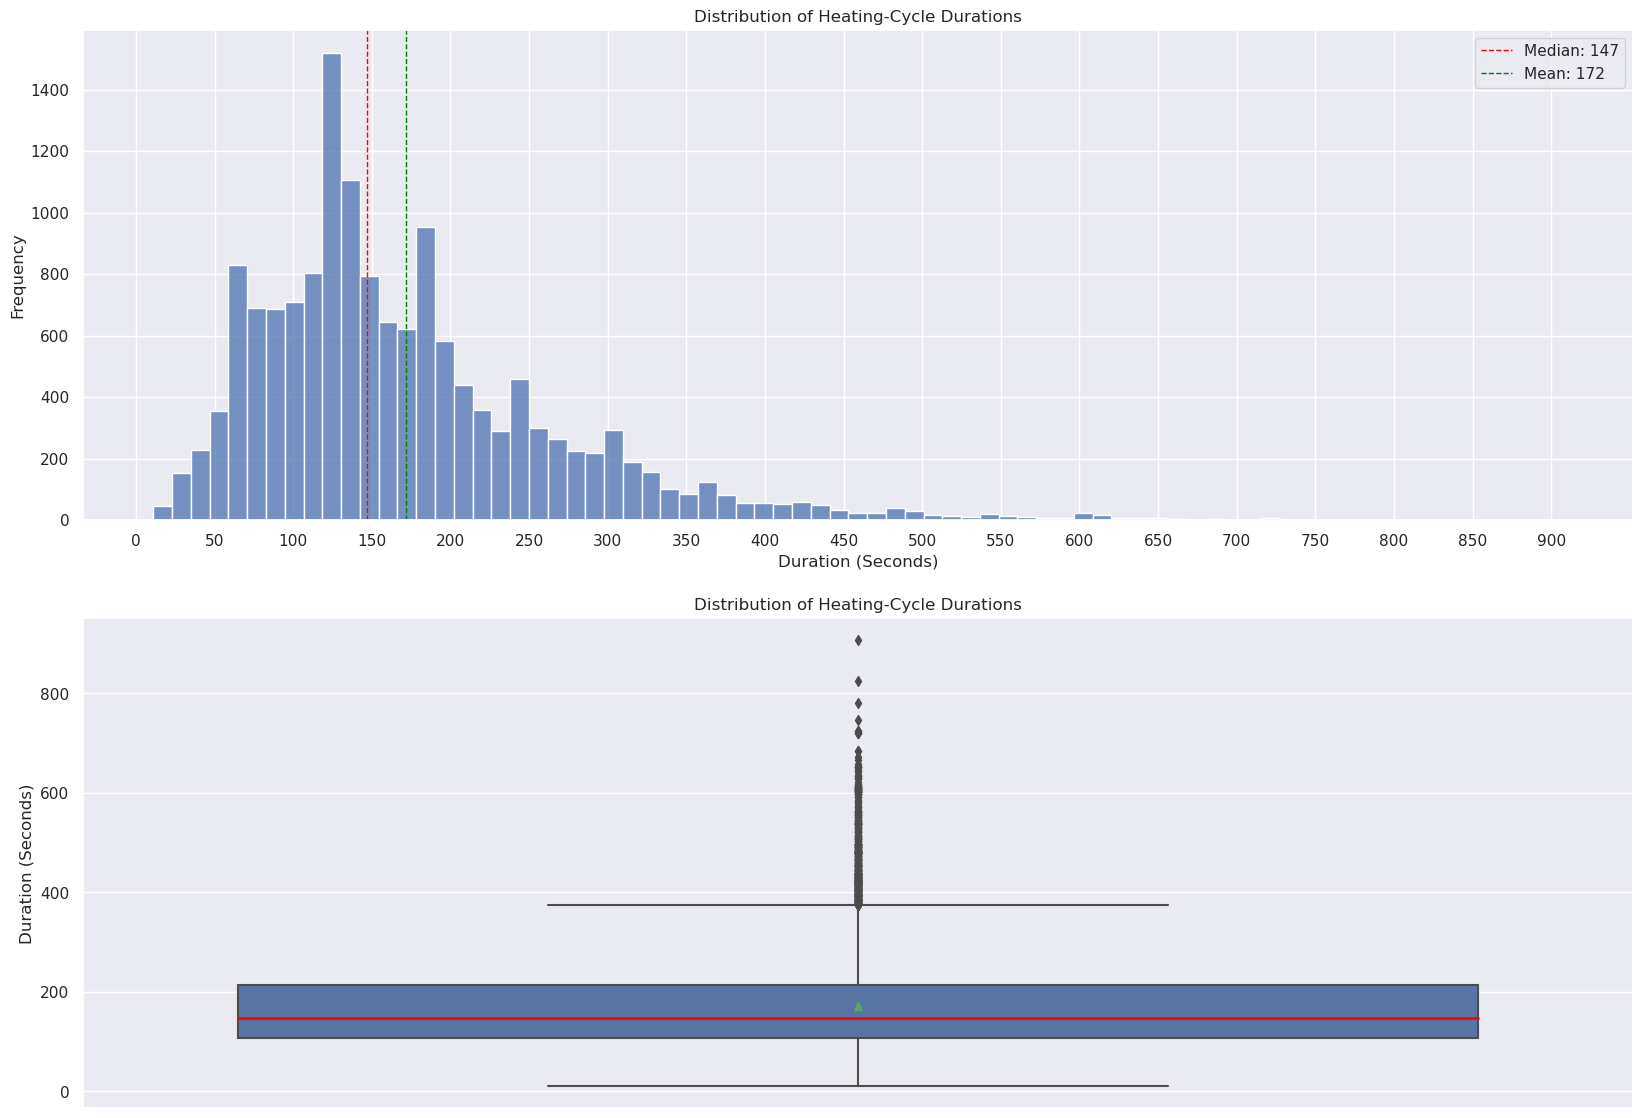

In [17]:
fig, axes = plt.subplots(2,1,figsize=(20,14))

sns.histplot(data=data_arc_en,x='arc_heating_interval',ax=axes[0],discrete=False,bins=75)

axes[0].set_title("Distribution of Heating-Cycle Durations")
axes[0].set_xlabel("Duration (Seconds)")
axes[0].set_ylabel("Frequency")
start = 0
end = 900
stepsize=50
axes[0].set_xticks(np.arange(start,end+stepsize,stepsize))



median_val = data_arc_en['arc_heating_interval'].median()
axes[0].axvline(
    x=median_val,
    color="red",
    linestyle="--",
    linewidth=1,
    label=f"Median: {median_val:.0f}"
)

mean_val = data_arc_en['arc_heating_interval'].mean()
axes[0].axvline(
    x=mean_val,
    color="green",
    linestyle="--",
    linewidth=1,
    label=f"Mean: {mean_val:.0f}"
)

axes[0].legend()


sns.boxplot(y=data_arc_en['arc_heating_interval'],ax=axes[1],medianprops={"color":"red","linewidth":2},showmeans=True)

axes[1].set_title("Distribution of Heating-Cycle Durations")
axes[1].set_ylabel("Duration (Seconds)")

plt.show()



As we can see, heating-cycle durations vary considerably, with cycles ranging from 25 seconds to more than 600 seconds, although most durations are concentrated between approximately 65 and 200 seconds. This variability should provide valuable information for our models to learn heating patterns and their relationships with measured temperatures.

#### The `key` Column

By definition, we expect multiple rows to share the same value in this column: each row corresponds to a heating cycle, and a secondary-refining batch can contain several heating cycles.

As noted earlier, there are no negative values in **`key`**, meaning that all values meet this validity check.

#### The `active_power` Column

As established earlier, all values in this column are valid.

#### The `reactive_power` Column

We will check the negative values in this column.

In [18]:
data_arc_en.loc[data_arc_en["reactive_power"] <=0]

,key,arc_heating_start,arc_heating_end,active_power,reactive_power,arc_heating_interval
9780,2116,2019-07-24 00:44:48,2019-07-24 00:46:37,0.495782,-715.504924,109.0


There is only one negative value in `reactive_power`. Although we do not know the precise nature of this data, it would be reasonable to suspect that a single negative observation among more than 14,000 records might be erroneous. We cannot prove this, however, so we will address the value later when preparing the data for modeling.

In [19]:
data_arc_en['key'].nunique()

3214

## Bulk Material Addition Data (`data_bulk_en`)

This dataset records the volume of each material added to the ladle furnace. Each column represents a material, while each row represents a secondary-refining batch. We expect only one row per `key` in this dataset.

In [20]:
data_bulk_en.head()

,key,bulk_1,bulk_2,bulk_3,bulk_4,bulk_5,bulk_6,bulk_7,bulk_8,bulk_9,bulk_10,bulk_11,bulk_12,bulk_13,bulk_14,bulk_15
0,1,NaN,NaN,NaN,43.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,206.0,NaN,150.0,154.0
1,2,NaN,NaN,NaN,73.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,206.0,NaN,149.0,154.0
2,3,NaN,NaN,NaN,34.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,205.0,NaN,152.0,153.0
3,4,NaN,NaN,NaN,81.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,207.0,NaN,153.0,154.0
4,5,NaN,NaN,NaN,78.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,203.0,NaN,151.0,152.0


In [21]:
data_bulk_en.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3129 entries, 0 to 3128
Data columns (total 16 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   key      3129 non-null   int64  
 1   bulk_1   252 non-null    float64
 2   bulk_2   22 non-null     float64
 3   bulk_3   1298 non-null   float64
 4   bulk_4   1014 non-null   float64
 5   bulk_5   77 non-null     float64
 6   bulk_6   576 non-null    float64
 7   bulk_7   25 non-null     float64
 8   bulk_8   1 non-null      float64
 9   bulk_9   19 non-null     float64
 10  bulk_10  176 non-null    float64
 11  bulk_11  177 non-null    float64
 12  bulk_12  2450 non-null   float64
 13  bulk_13  18 non-null     float64
 14  bulk_14  2806 non-null   float64
 15  bulk_15  2248 non-null   float64
dtypes: float64(15), int64(1)
memory usage: 391.2 KB


All columns except `key` contain missing values. This is expected because each `bulk` column represents a material that may be added to the steel, and not all materials are added during every secondary-refining batch. These missing values could be replaced with zero if a model needs to be trained without null values.

The bulk-material dataset contains 3,129 rows representing 3,129 complete secondary-refining batches. Recall that the electrode dataset contained 3,214 unique `key` values representing complete secondary-refining batches. This might indicate that some batches received no bulk material additions, but we will need to investigate before preparing the modeling data.

There are 16 columns:
- `key` — an identifier for an entire secondary-refining batch, from the introduction of liquid steel into the ladle furnace until it is released for casting.
- `bulk_1` through `bulk_15` — the quantities of the individual materials added during a complete secondary-refining batch.

In [22]:
data_bulk_en.describe()

,key,bulk_1,bulk_2,bulk_3,bulk_4,bulk_5,bulk_6,bulk_7,bulk_8,bulk_9,bulk_10,bulk_11,bulk_12,bulk_13,bulk_14,bulk_15
count,3129.000000,252.000000,22.000000,1298.000000,1014.000000,77.000000,576.000000,25.000000,1.0,19.000000,176.000000,177.000000,2450.000000,18.000000,2806.000000,2248.000000
mean,1624.383509,39.242063,253.045455,113.879045,104.394477,107.025974,118.925347,305.600000,49.0,76.315789,83.284091,76.819209,260.471020,181.111111,170.284747,160.513345
std,933.337642,18.277654,21.180578,75.483494,48.184126,81.790646,72.057776,191.022904,NaN,21.720581,26.060347,59.655365,120.649269,46.088009,65.868652,51.765319
min,1.000000,10.000000,228.000000,6.000000,12.000000,11.000000,17.000000,47.000000,49.0,63.000000,24.000000,8.000000,53.000000,151.000000,16.000000,1.000000
25%,816.000000,27.000000,242.000000,58.000000,72.000000,70.000000,69.750000,155.000000,49.0,66.000000,64.000000,25.000000,204.000000,153.250000,119.000000,105.000000
50%,1622.000000,31.000000,251.500000,97.500000,102.000000,86.000000,100.000000,298.000000,49.0,68.000000,86.500000,64.000000,208.000000,155.500000,151.000000,160.000000
75%,2431.000000,46.000000,257.750000,152.000000,133.000000,132.000000,157.000000,406.000000,49.0,70.500000,102.000000,106.000000,316.000000,203.500000,205.750000,205.000000
max,3241.000000,185.000000,325.000000,454.000000,281.000000,603.000000,503.000000,772.000000,49.0,147.000000,159.000000,313.000000,1849.000000,305.000000,636.000000,405.000000


In [23]:
print(f"Percentage of Batches Receiving Each Material Addition:\n{(data_bulk_en.drop('key',axis=1).count() / data_bulk_en['key'].count()).round(4)}")

Percentage of Batches Receiving Each Material Addition:
bulk_1     0.0805
bulk_2     0.0070
bulk_3     0.4148
bulk_4     0.3241
bulk_5     0.0246
bulk_6     0.1841
bulk_7     0.0080
bulk_8     0.0003
bulk_9     0.0061
bulk_10    0.0562
bulk_11    0.0566
bulk_12    0.7830
bulk_13    0.0058
bulk_14    0.8968
bulk_15    0.7184
dtype: float64


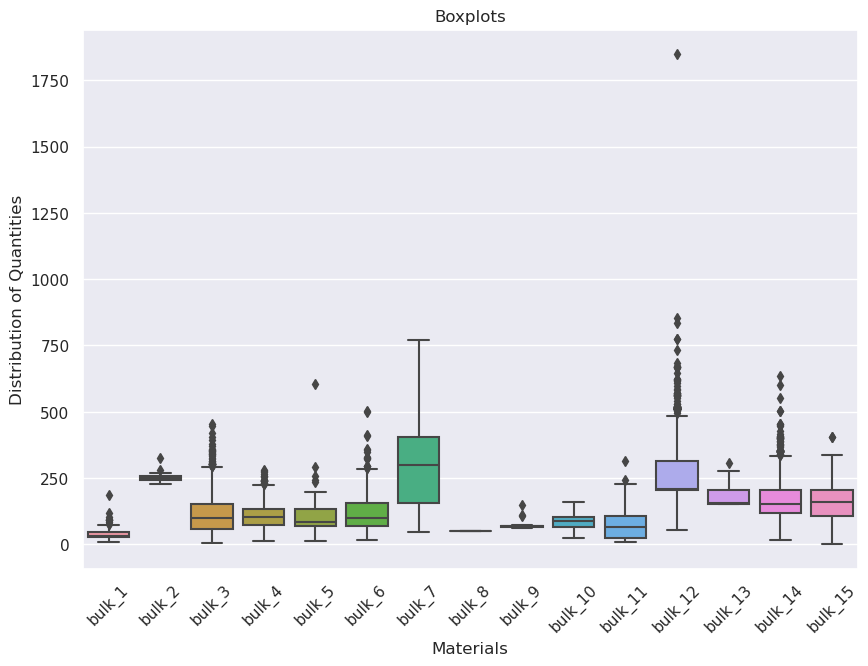

In [24]:
fig, ax = plt.subplots(figsize=(10,7))

sns.boxplot(data=data_bulk_en.drop("key",axis=1),ax=ax)

ax.set_title("Boxplots")
ax.set_xlabel("Materials")
ax.set_ylabel("Distribution of Quantities")
ax.set_xticklabels(ax.get_xticklabels(),rotation=45)

plt.show()



As observed, certain materials are added much more frequently than others. **`bulk_12`**, **`bulk_14`**, and **`bulk_15`** are added to most batches, with frequencies of 78%, 90%, and 72%, respectively. The materials `bulk_3`, `bulk_4`, and `bulk_6` are also added to a considerable number of batches, at rates of 41%, 32%, and 18%, respectively. The remaining materials are less common, although the total quantity added varies substantially from one material to another. For example, `bulk_7` is added to fewer than 1% of batches but has a widely dispersed quantity distribution. We can assess the predictive value of these variables before preparing the model data. For now, it is clear that `bulk_8` may offer very little value because it was added to only one secondary-refining batch.

## Bulk Material Addition Timestamp Data

In [25]:
data_bulk_time_en.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3129 entries, 0 to 3128
Data columns (total 16 columns):
 #   Column   Non-Null Count  Dtype         
---  ------   --------------  -----         
 0   key      3129 non-null   int64         
 1   bulk_1   252 non-null    datetime64[ns]
 2   bulk_2   22 non-null     datetime64[ns]
 3   bulk_3   1298 non-null   datetime64[ns]
 4   bulk_4   1014 non-null   datetime64[ns]
 5   bulk_5   77 non-null     datetime64[ns]
 6   bulk_6   576 non-null    datetime64[ns]
 7   bulk_7   25 non-null     datetime64[ns]
 8   bulk_8   1 non-null      datetime64[ns]
 9   bulk_9   19 non-null     datetime64[ns]
 10  bulk_10  176 non-null    datetime64[ns]
 11  bulk_11  177 non-null    datetime64[ns]
 12  bulk_12  2450 non-null   datetime64[ns]
 13  bulk_13  18 non-null     datetime64[ns]
 14  bulk_14  2806 non-null   datetime64[ns]
 15  bulk_15  2248 non-null   datetime64[ns]
dtypes: datetime64[ns](15), int64(1)
memory usage: 391.2 KB


All columns except `key` contain missing values. This is expected because each `bulk` column represents a material that may be added to the steel, and not all materials are added during every secondary-refining batch.

The bulk-material addition timestamp dataset contains 3,129 rows representing 3,129 complete secondary-refining batches. Recall that the electrode dataset contained 3,214 unique `key` values representing complete secondary-refining batches. This might indicate that some batches did not receive material additions, but we will need to investigate before preparing the modeling data.

There are 16 columns:
- `key` — an identifier for an entire secondary-refining batch, from the introduction of liquid steel into the ladle furnace until it is released for casting.
- `bulk_1` through `bulk_15` — the timestamps when each material was added during a complete secondary-refining batch.

## Gas Purging Process Data

In [26]:
data_gas_en.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3239 entries, 0 to 3238
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   key     3239 non-null   int64  
 1   gas_1   3239 non-null   float64
dtypes: float64(1), int64(1)
memory usage: 50.7 KB


There are no missing values in this dataset.

The gas dataset contains 3,239 rows representing 3,239 complete secondary-refining batches. Recall that the electrode dataset contained 3,214 unique `key` values representing complete secondary-refining batches. This could mean that some secondary-refining batches did not receive gas purging, but we will need to investigate before preparing the modeling data.

There are two columns:
- `key` — an identifier for a secondary-refining batch, from the introduction of liquid steel into the ladle furnace until it is released for casting.
- `gas_1` — the total amount of gas added to the batch.

**NOTE:**

An obvious complication with this dataset is that it does not contain timestamps for gas-purging events. Consequently, we cannot determine when gas was added to a batch. **`gas_1`** represents only the total gas added over the entire batch. We may have to ignore this dataset because these gas quantities cannot be assigned to specific moments in the heating process. This limitation cannot be overlooked, and it would be difficult to justify arbitrarily distributing the batch's total gas volume among its heating cycles.

In [27]:
data_gas_en.describe()

,key,gas_1
count,3239.000000,3239.000000
mean,1621.861377,11.002062
std,935.386334,6.220327
min,1.000000,0.008399
25%,812.500000,7.043089
50%,1622.000000,9.836267
75%,2431.500000,13.769915
max,3241.000000,77.995040


<AxesSubplot:xlabel='gas_1', ylabel='Count'>

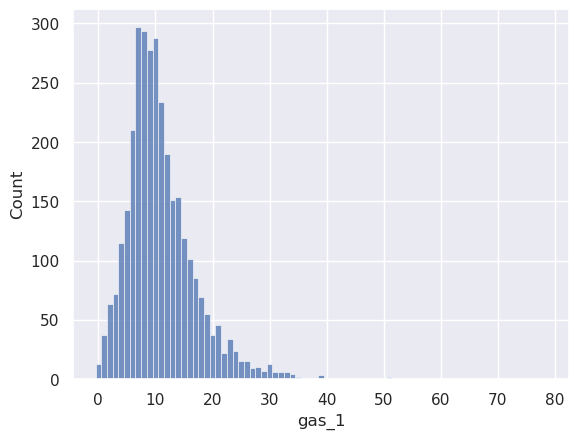

In [28]:
sns.histplot(data_gas_en,x='gas_1',discrete=True)

The gas-purging quantities are not particularly dispersed, with most values concentrated around 5 to 15 per batch. I suspect there may be a direct correlation between these quantities and the number of heating cycles per batch, which is one possible reason to maintain our decision not to use gas-purging data. A correlation between more heating cycles and greater gas additions could suggest that purging is performed multiple times, perhaps whenever the steel is heated or a material is added. Although we cannot confirm this, it would make the precise timing of purging especially important. In any case, not knowing when purging occurred makes this variable difficult to use in a model that depends on timestamps to identify when each operation took place during a heating interval.

## Temperature Measurement Records

In [29]:
data_temp_en.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 15907 entries, 0 to 15906
Data columns (total 3 columns):
 #   Column         Non-Null Count  Dtype         
---  ------         --------------  -----         
 0   key            15907 non-null  int64         
 1   sampling_time  15907 non-null  datetime64[ns]
 2   temperature    13006 non-null  float64       
dtypes: datetime64[ns](1), float64(1), int64(1)
memory usage: 372.9 KB


There are missing values in the **`temperature`** column. This means temperature measurements were recorded, but their numerical values are not available. We may need to exclude those rows from training because we cannot train the model to predict a temperature for which the target value is unknown.

The temperature dataset contains 15,907 rows representing 15,907 temperature measurements. Each record refers to an individual measurement, while each secondary-refining batch, identified by **`key`**, can have multiple temperature measurements.

There are three columns:
- `key` — an identifier for a secondary-refining batch, from the introduction of liquid steel into the ladle furnace until it is released for casting.
- `sampling_time` — the timestamp when the temperature measurement was taken.
- `temperature` — the temperature in degrees Celsius associated with that measurement.

In [30]:
sampling_per_key = data_temp_en.groupby('key').size()

sampling_per_key.describe()

count    3216.000000
mean        4.946206
std         1.793169
min         1.000000
25%         4.000000
50%         5.000000
75%         6.000000
max        16.000000
dtype: float64

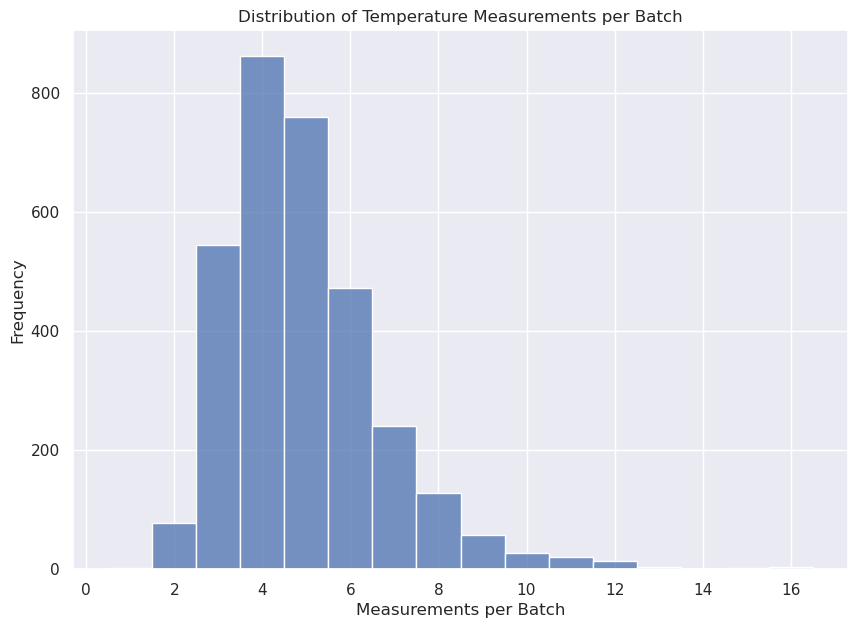

In [31]:
fig, ax = plt.subplots(figsize=(10,7))

sns.histplot(x = sampling_per_key,discrete=True,ax=ax)

ax.set_title("Distribution of Temperature Measurements per Batch")
ax.set_xlabel("Measurements per Batch")
ax.set_ylabel("Frequency")

plt.show()

In [32]:
sampling_frequency_table = data_temp_en.groupby("key").size().rename("samplings")

print(f"Average temperature measurements per secondary-refining batch: {sampling_frequency_table.mean():.2f}")
print(f"Minimum temperature measurements per secondary-refining batch: {sampling_frequency_table.min():.2f}")
print(f"Maximum temperature measurements per secondary-refining batch: {sampling_frequency_table.max():.2f}")


Average temperature measurements per secondary-refining batch: 4.95
Minimum temperature measurements per secondary-refining batch: 1.00
Maximum temperature measurements per secondary-refining batch: 16.00


In [33]:
sampling_frequency_table = (
    sampling_frequency_table.value_counts()
    .rename_axis("samplings_per_batch", axis=0)
    .reset_index(name="frequency")
)

sampling_frequency_table["relative_frequency"] = sampling_frequency_table["frequency"] / sampling_frequency_table["frequency"].sum()

In [34]:
sampling_frequency_table

,samplings_per_batch,frequency,relative_frequency
0,4,862,0.268035
1,5,759,0.236007
2,3,545,0.169465
3,6,473,0.147077
4,7,240,0.074627
5,8,128,0.039801
6,2,78,0.024254
7,9,57,0.017724
8,10,27,0.008396
9,11,21,0.006530


In [35]:
print(f"Relative Frequency of Batches with 4 or 5 Temperature Measurements: {sampling_frequency_table.loc[sampling_frequency_table['samplings_per_batch'].isin([4,5]),'relative_frequency'].sum()*100:.2f}")

Relative Frequency of Batches with 4 or 5 Temperature Measurements: 50.40


As shown, every batch received at least one temperature measurement, and some received as many as 16. Most batches had four or five temperature measurements, representing approximately 50% of all batches in the measurement dataset.

Although these figures are similar to the average and maximum heating-cycle counts, we cannot conclude that the two variables are directly correlated. We would need to investigate the relationship between these distributions at the batch level.

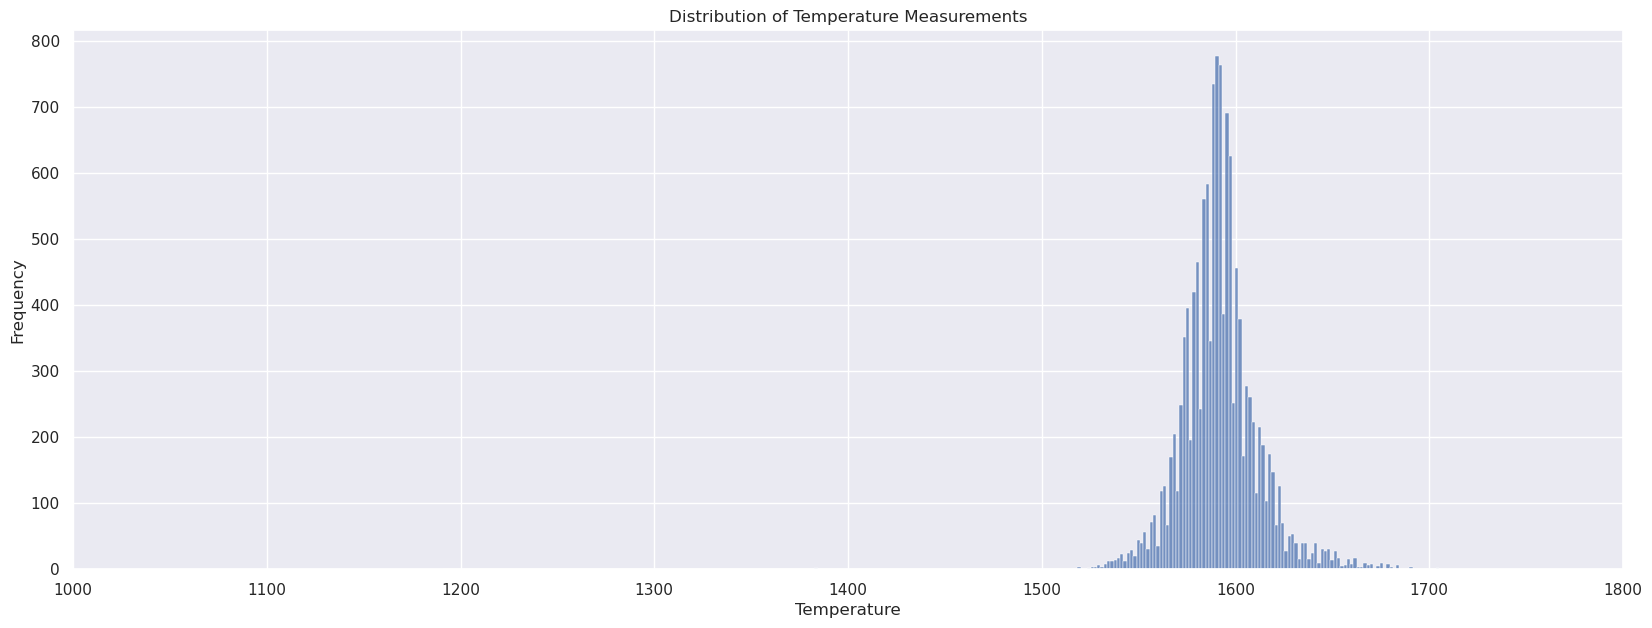

In [36]:
fig,ax = plt.subplots(figsize=(20,7))

sns.histplot(data_temp_en,x='temperature',discrete=False,ax=ax)

ax.set_title("Distribution of Temperature Measurements")
ax.set_xlabel("Temperature")
ax.set_ylabel("Frequency")

stepsize=100
start = 1000
end = 1800

ax.set_xticks(np.arange(start,end+stepsize,stepsize))


plt.show()

In [37]:
data_temp_en['temperature'].describe()

count    13006.000000
mean      1591.840920
std         21.375851
min       1191.000000
25%       1581.000000
50%       1591.000000
75%       1601.000000
max       1705.000000
Name: temperature, dtype: float64

The mean recorded temperature is $1591.84^oC$, while the middle 50% of the observations range from $1581^oC$ to $1601^oC$. It appears that Steelproof tries to maintain temperatures near this range, which may be considered desirable operating values. According to Rizzo (2006) and Rocha (2026), the ideal temperature for melting steel is $1600^oC$. That does not mean the ideal temperature inside the ladle furnace or the ideal final steel-casting temperature is exactly $1600^oC$, because target temperatures vary substantially by steel grade and desired final product. Nevertheless, this is a useful reference point.

Our recorded temperatures range from $1191^oC$ to $1705^oC$, indicating substantial variation even if established operating practices are followed. The standard deviation of $21.38^oC$ shows some dispersion in the data.

Very low temperatures are probably measurement or recording errors, given that steel begins to solidify somewhere in the 1400–1500°C range. We will need to investigate an appropriate minimum temperature threshold and remove values below it. Ideally, Steelproof would provide an operating minimum based on its own process constraints.

Number of missing temperature measurements: 2901
Earliest timestamp in the distribution of all temperatures: 2019-05-03 11:16:18
Earliest timestamp in the distribution of all temperatures: 2019-09-01 04:38:08
Earliest timestamp among missing temperature values: 2019-08-06 03:24:43
Latest timestamp among missing temperature values: 2019-09-01 04:38:08


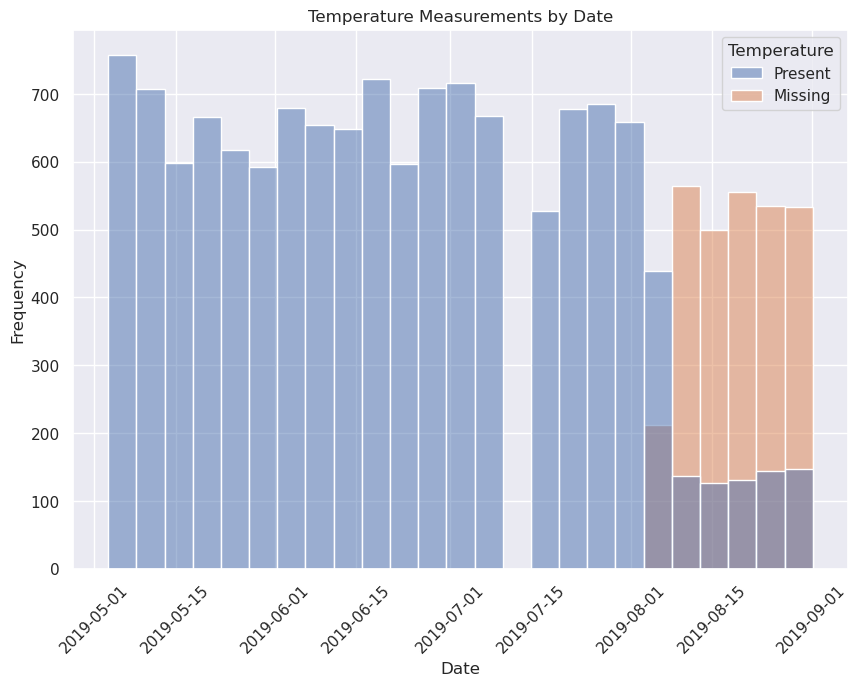

In [38]:
data_temp_en['missing_temp'] = np.where(data_temp_en['temperature'].isna(), "missing_temp", "present_temp")

print("Number of missing temperature measurements:",(data_temp_en['missing_temp'] == 'missing_temp').sum())

print("Earliest timestamp in the distribution of all temperatures:",data_temp_en.loc[:,'sampling_time'].min())
print("Earliest timestamp in the distribution of all temperatures:",data_temp_en.loc[:,'sampling_time'].max())
print("Earliest timestamp among missing temperature values:",data_temp_en.loc[data_temp_en['missing_temp'] == 'missing_temp','sampling_time'].min())
print("Latest timestamp among missing temperature values:",data_temp_en.loc[data_temp_en['missing_temp'] == 'missing_temp','sampling_time'].max())

fig,ax = plt.subplots(figsize=(10,7))

sns.histplot(data=data_temp_en,x='sampling_time',ax=ax,hue='missing_temp')

ax.set_title("Temperature Measurements by Date")
ax.set_xlabel("Date")
ax.set_ylabel("Frequency")

legend = ax.get_legend()

for handle, new_label in zip(
    legend.get_texts(),
    ['Present', 'Missing']
):
    handle.set_text(new_label)

legend.set_title('Temperature')

plt.xticks(rotation=45)

plt.show()

There are 2,901 missing temperature values that we will need to address in the analysis. Because temperature is our prediction target, we cannot simply impute missing target values. We will probably need to remove those observations and work with the remaining data.

These missing temperature values occur near the end of the dataset, from 2019-08-05 to 2019-09-01. There are still some valid temperatures at the end of the dataset, but they are much less frequent than missing values.

In [39]:
data_temp_en['key'].nunique()

3216

The temperature measurements correspond to 3,216 secondary-refining batches, meaning that many batches contain more than one temperature measurement.

## Wire Material Addition Data

This dataset records the quantities of materials added as cored wire containing substances used to control the final chemical composition of the steel.

In [40]:
data_wire_en.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3081 entries, 0 to 3080
Data columns (total 10 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   key     3081 non-null   int64  
 1   wire_1  3055 non-null   float64
 2   wire_2  1079 non-null   float64
 3   wire_3  63 non-null     float64
 4   wire_4  14 non-null     float64
 5   wire_5  1 non-null      float64
 6   wire_6  73 non-null     float64
 7   wire_7  11 non-null     float64
 8   wire_8  19 non-null     float64
 9   wire_9  29 non-null     float64
dtypes: float64(9), int64(1)
memory usage: 240.8 KB


All columns except `key` contain missing values. This is expected because each `wire` column represents a material added to the steel, and not every material is added during every secondary-refining batch. These missing values could be replaced with zero if a model needs to be trained without null values.

The wire-material dataset contains 3,081 rows representing 3,081 complete secondary-refining batches. Recall that the electrode dataset contained 3,214 unique `key` values representing complete secondary-refining batches. This might indicate that some batches did not receive material additions, but we will need to investigate before preparing the modeling data.

There are ten columns:
- `key` — an identifier for an entire secondary-refining batch, from the introduction of liquid steel into the ladle furnace until it is released for casting.
- `wire_1` through `wire_9` — the quantities of the individual materials added during the complete secondary-refining batch.

In [41]:
data_wire_en.describe()

,key,wire_1,wire_2,wire_3,wire_4,wire_5,wire_6,wire_7,wire_8,wire_9
count,3081.000000,3055.000000,1079.000000,63.000000,14.000000,1.000,73.000000,11.000000,19.000000,29.000000
mean,1623.426485,100.895853,50.577323,189.482681,57.442841,15.132,48.016974,10.039007,53.625193,34.155752
std,932.996726,42.012518,39.320216,99.513444,28.824667,NaN,33.919845,8.610584,16.881728,19.931616
min,1.000000,1.918800,0.030160,0.144144,24.148801,15.132,0.034320,0.234208,45.076721,4.622800
25%,823.000000,72.115684,20.193680,95.135044,40.807002,15.132,25.053600,6.762756,46.094879,22.058401
50%,1619.000000,100.158234,40.142956,235.194977,45.234282,15.132,42.076324,9.017009,46.279999,30.066399
75%,2434.000000,126.060483,70.227558,276.252014,76.124619,15.132,64.212723,11.886057,48.089603,43.862003
max,3241.000000,330.314424,282.780152,385.008668,113.231044,15.132,180.454575,32.847674,102.762401,90.053604


Percentage of Batches Receiving Each Material Addition:
wire_1    0.9916
wire_2    0.3502
wire_3    0.0204
wire_4    0.0045
wire_5    0.0003
wire_6    0.0237
wire_7    0.0036
wire_8    0.0062
wire_9    0.0094
dtype: float64


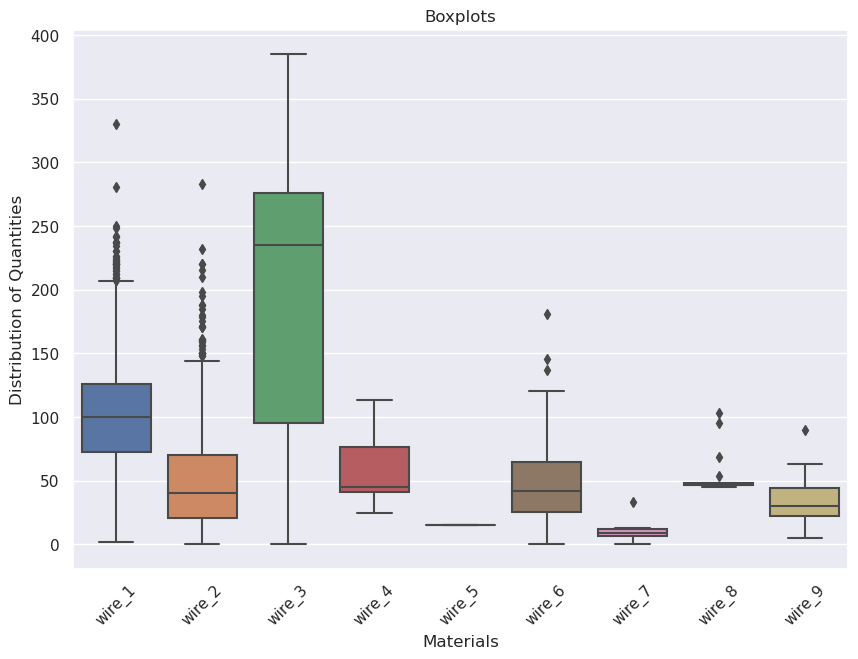

In [42]:
print(f"Percentage of Batches Receiving Each Material Addition:\n{(data_wire_en.drop('key',axis=1).count() / data_wire_en['key'].count()).round(4)}")

fig, ax = plt.subplots(figsize=(10,7))

sns.boxplot(data=data_wire_en.drop("key",axis=1),ax=ax)

ax.set_title("Boxplots")
ax.set_xlabel("Materials")
ax.set_ylabel("Distribution of Quantities")
ax.set_xticklabels(ax.get_xticklabels(),rotation=45)

plt.show()



As we can see, most batches received **`wire_1`**, which was added in 99% of batches. In second place, `wire_2` was added to 35% of batches. All other materials were rarely added, with none appearing in more than 2.4% of batches. In absolute terms, `wire_5` was added to only one batch, while `wire_3` was added to 63 batches, making it the third most commonly added material after `wire_1` and `wire_2`, which appeared in more than 3,055 and 1,071 batches, respectively. We will need to assess the predictive value of these variables before model training.

## Wire Material Addition Timestamp Data

In [43]:
data_wire_time_en.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3081 entries, 0 to 3080
Data columns (total 10 columns):
 #   Column  Non-Null Count  Dtype         
---  ------  --------------  -----         
 0   key     3081 non-null   int64         
 1   wire_1  3055 non-null   datetime64[ns]
 2   wire_2  1079 non-null   datetime64[ns]
 3   wire_3  63 non-null     datetime64[ns]
 4   wire_4  14 non-null     datetime64[ns]
 5   wire_5  1 non-null      datetime64[ns]
 6   wire_6  73 non-null     datetime64[ns]
 7   wire_7  11 non-null     datetime64[ns]
 8   wire_8  19 non-null     datetime64[ns]
 9   wire_9  29 non-null     datetime64[ns]
dtypes: datetime64[ns](9), int64(1)
memory usage: 240.8 KB


All columns except `key` contain missing values. This is expected because each material column represents a material that may be added to the steel, and not every material is added during every secondary-refining batch.

The wire-material timestamp dataset contains 3,081 rows representing 3,081 complete secondary-refining batches. Recall that the electrode dataset contained 3,214 unique `key` values representing complete secondary-refining batches. This might indicate that some batches did not receive material additions, but we will need to investigate before preparing the modeling data.

There are ten columns:
- `key` — an identifier for an entire secondary-refining batch, from the introduction of liquid steel into the ladle furnace until it is released for casting.
- `wire_1` through `wire_9` — the timestamps at which each material was added during a complete secondary-refining batch.

## COMBINED DATA ANALYSIS

First, let us analyze the relationship between temperature measurements and heating cycles.

In [44]:
last_temp:pd.DataFrame  = data_temp_en.groupby('key')[['sampling_time']].max()

last_heating:pd.DataFrame = (
    data_arc_en.loc[
        data_arc_en.groupby('key')['arc_heating_end'].idxmax(),
        ['key', 'arc_heating_start', 'arc_heating_end']
    ]
    .set_index('key')
)
comparison = last_temp.join(last_heating,on='key',how='outer')

comparison['time_difference'] = (comparison['sampling_time'] - comparison['arc_heating_end']).dt.total_seconds()

In [45]:
print("Number of batches where the last temperature measurement occurs after the final heating cycle ends:",(comparison["time_difference"] > 0).sum())
print("Number of batches where the last temperature measurement occurs before the final heating cycle ends:",(comparison["time_difference"] < 0).sum())
print("Number of batches where the last temperature measurement coincides with the end of the final heating cycle:",(comparison["time_difference"] == 0).sum())

Number of batches where the last temperature measurement occurs after the final heating cycle ends: 3045
Number of batches where the last temperature measurement occurs before the final heating cycle ends: 169
Number of batches where the last temperature measurement coincides with the end of the final heating cycle: 0


As shown, most batches have a temperature measurement after the final heating cycle. There are only 169 batches in which a heating cycle ended after the last recorded temperature measurement. Remember that we need a temperature measurement before and after each heating cycle to train the model.

In [46]:
print("Number of batches where the last measurement occurs during the final heating cycle:",((comparison['sampling_time'] > comparison['arc_heating_start']) & (comparison['sampling_time'] < comparison['arc_heating_end'])).sum())

Number of batches where the last measurement occurs during the final heating cycle: 0


We also observe that no temperature measurements occur during the final heating cycle. This is useful to verify, but before preparing the modeling data, we will need to investigate more thoroughly whether any heating cycles—not necessarily the final cycle—have temperature measurements taken before heating ends. I suspect that this does not happen in our data because it does not seem to be part of the normal secondary-refining sequence. Nevertheless, we must verify it because the model can only be trained using information available before the temperature measurement that serves as its target.

In [47]:

# Here we create an identifier for each heating cycle within a secondary-
# refining batch. This lets us identify both the batch and the specific
# heating cycle

data_arc_en = data_arc_en.sort_values(['key','arc_heating_start'])
data_arc_en['heating_cycle_no'] = data_arc_en.groupby('key').cumcount() + 1

In [48]:
## Create a combined long-format dataset containing all relevant data

data_arc_time_long = data_arc_en.drop(['active_power','reactive_power','arc_heating_interval'],axis=1).melt(id_vars=['key','heating_cycle_no'],value_name='timestamp')

data_bulk_time_long = data_bulk_time_en.melt(id_vars='key',value_name='timestamp').dropna()

data_wire_time_long = data_wire_time_en.melt(id_vars='key',value_name='timestamp').dropna()

data_temp_en_long = data_temp_en.rename({'sampling_time':'timestamp'},axis=1)
data_temp_en_long['variable'] = 'sampling'
data_temp_en_long = data_temp_en_long[['key','variable','timestamp','temperature']]

data_long:pd.DataFrame = pd.concat([data_arc_time_long,data_bulk_time_long,data_wire_time_long,data_temp_en_long])

data_long = data_long.sort_values(by=['key','timestamp'])

In [49]:
datasets = {
    "arc": data_arc_en,
    "bulk": data_bulk_en,
    "bulk_time": data_bulk_time_en,
    "gas": data_gas_en,
    "temp": data_temp_en,
    "wire": data_wire_en,
    "wire_time": data_wire_time_en,
}

for name, df in datasets.items():
    print(
        name,
        "shape:", df.shape,
        "duplicates:", df.duplicated().sum(),
        "unique keys:", df["key"].nunique()
    )

arc shape: (14876, 7) duplicates: 0 unique keys: 3214
bulk shape: (3129, 16) duplicates: 0 unique keys: 3129
bulk_time shape: (3129, 16) duplicates: 0 unique keys: 3129
gas shape: (3239, 2) duplicates: 0 unique keys: 3239
temp shape: (15907, 4) duplicates: 0 unique keys: 3216
wire shape: (3081, 10) duplicates: 0 unique keys: 3081
wire_time shape: (3081, 10) duplicates: 0 unique keys: 3081


Example of a Secondary-Refining Batch

In [50]:
data_long.loc[data_long['key'] == random.randint(0,data_long['key'].max())]

,key,heating_cycle_no,variable,timestamp,temperature
3924,847,1.0,arc_heating_start,2019-06-03 18:19:00,NaN
18800,847,1.0,arc_heating_end,2019-06-03 18:21:23,NaN
4254,847,NaN,sampling,2019-06-03 18:24:37,1571.0
3925,847,2.0,arc_heating_start,2019-06-03 18:25:01,NaN
41489,847,NaN,bulk_14,2019-06-03 18:27:12,NaN
18801,847,2.0,arc_heating_end,2019-06-03 18:31:28,NaN
793,847,NaN,wire_1,2019-06-03 18:33:22,NaN
3926,847,3.0,arc_heating_start,2019-06-03 18:33:37,NaN
16457,847,NaN,bulk_6,2019-06-03 18:35:07,NaN
32102,847,NaN,bulk_11,2019-06-03 18:35:07,NaN


The cell above can be run repeatedly to examine different examples of complete secondary-refining batches. As we can see, nearly every batch starts without an initial temperature measurement and proceeds directly to heating. This means that the initial interval cannot be used for training. We also observe many examples of consecutive temperature measurements with no operations recorded between them. These intervals without heating will also be excluded from training.

In [51]:
measurements_per_batch = data_temp_en.groupby('key').size()
print("Number of batches with at least two temperature measurements:",(measurements_per_batch >=2).sum())
print("Number of temperature measurements potentially usable as training targets:", (measurements_per_batch-1).clip(lower=0).sum())

Number of batches with at least two temperature measurements: 3214
Number of temperature measurements potentially usable as training targets: 12691


Here, we can see that we may have as many as 12,691 valid target temperatures for training. Most batches—3,214, to be exact—have at least two temperature measurements. Batches with only one temperature measurement cannot be used for training. We will need to determine which measurements have missing temperature values and exclude them from the training targets.

Let us analyze the time interval between consecutive measurements:

In [52]:
temp_analysis:pd.DataFrame = data_temp_en_long.sort_values(['key','timestamp']).copy()

temp_analysis['time_since_last_temp'] = (temp_analysis['timestamp'] - temp_analysis.groupby('key')['timestamp'].shift()).dt.total_seconds()

temp_analysis['time_since_last_temp'].describe()

count    12691.000000
mean       466.235521
std        467.544059
min          3.000000
25%        202.000000
50%        388.000000
75%        635.000000
max      14663.000000
Name: time_since_last_temp, dtype: float64

In [53]:
temp_analysis_iqr = temp_analysis['time_since_last_temp'].quantile(0.75) - temp_analysis['time_since_last_temp'].quantile(0.25)

print(temp_analysis_iqr)

433.0


On average, there are 466 seconds between consecutive temperature measurements. The minimum is three seconds and the maximum is 14,663 seconds, while the middle 50% range from 202 to 635 seconds.

# MODELING HYPOTHESES

I have identified the following algorithms for training our models:

- **CatBoost:**
  - This model uses gradient boosting with decision trees and can identify nonlinear relationships and complex interactions among variables. With predictors such as initial temperature, heating duration, power, and material additions, I believe a model capable of learning complex relationships is necessary, even if a substantial part of the relationships between these variables might be approximately linear. CatBoost could therefore generalize well and also offers convenient data preprocessing capabilities.
- **LightGBM:**
  - LightGBM also uses gradient boosting, but with different training strategies. It offers efficient training and can capture nonlinear relationships. I consider it an excellent alternative to compare against CatBoost.
- **RandomForestRegressor (scikit-learn):**
  - This is a reference model that uses an ensemble of decision trees without boosting. It will provide a useful comparison for evaluating tree-based models **without** boosting.
- **Ridge (scikit-learn; optional):**
  - An optional linear benchmark. Because some relationships in our data may be approximately linear, it could be useful to understand what a simple regression model can achieve. I selected Ridge because its L2 regularization makes it less sensitive than ordinary linear regression to instability when predictors are strongly linearly related. This can reduce the risk of overfitting.

# KEY PERFORMANCE INDICATORS (KPIs)

The following will be our main performance indicators:

- **MAE (Mean Absolute Error), $\leq 10^\circ\mathrm{C}$:**
  - A measure expressed in the same temperature units as the target, representing the average absolute prediction error. A highly interpretable KPI.
- **RMSE (Root Mean Squared Error), $\leq 15^\circ\mathrm{C}$:**
  - A measure that penalizes larger errors more strongly and may be more informative if the model makes some very large prediction errors. It is also easy to interpret because it uses the same units as the target.
- **REAL-WORLD CHECK: Improvement over a simple baseline, $\geq 20\%$:**
  - If we consider a simple model that predicts the previous temperature measurement, $\hat{T}=T_{1}$, we expect to see a significant improvement over it.
  - Improvement is defined as: $I_{MAE} = \frac{MAE_{baseline} - MAE_{model}}{MAE_{baseline}} \times 100\%$.

For these thresholds, I used the study by Kavić (2025) as a reference. That study trained a model that achieved an MAE of $6.10^\circ\mathrm{C}$ and an RMSE of $9.10^\circ\mathrm{C}$, but it had access to much more detailed information, such as timestamps for gas-purging operations. I therefore do not necessarily expect our model to reach the same level of performance.

# EXPERIMENTAL DESIGN

To train and compare models, I will first reserve 10–20% of the data for final testing and use the remaining 80–90% for training and validation during model optimization. This split will respect secondary-refining batches, so heating cycles belonging to one batch will not be divided between the training and test sets. To achieve this, I plan to use scikit-learn's `GroupShuffleSplit` so that the data are partitioned correctly by each batch's **`key`**.

First, I will apply cross-validation to all models. Because multiple observations belong to the same batch, we cannot use ordinary cross-validation, which could place observations from the same batch in different datasets. I will instead use group-aware cross-validation based on **`key`**, specifically scikit-learn's `GroupKFold`.

I will also perform feature engineering. The datasets contain relatively rich information, so we can create numerous combinations of variables that might be useful to our models, including elapsed times between different heating stages, material additions, and temperature measurements. Examples include different heating-cycle durations, the number of heating cycles, and whether materials were added during or after a heating cycle.

Part of this data engineering will involve aggregating information associated with material-addition events, such as quantities and the corresponding time intervals, and doing the same for heating cycles.

Hyperparameter tuning will also be useful for the applicable models.

For each model, I expect to use the following tuning strategies:

- **CatBoost:** Optimize hyperparameters such as **`depth`**, **`learning_rate`**, and **`iterations`** to improve predictions while controlling overfitting.
- **LightGBM:** Optimize **`num_leaves`**, **`max_depth`**, **`min_child_samples`**, **`learning_rate`**, and **`n_estimators`** to improve predictions while balancing model complexity and training efficiency.
- **RandomForestRegressor:** Optimize **`n_estimators`**, **`max_depth`**, **`min_samples_leaf`**, and **`max_features`** to control tree complexity and minimize error.
- **Ridge (scikit-learn):** If trained, this model will require feature scaling with scikit-learn's **`StandardScaler`** and optimization of **`alpha`** to stabilize the linear regression coefficients and handle linear relationships between predictors.

MAE will be the primary KPI used for model selection, so our experimental strategies will focus directly on reducing it. RMSE will serve as an additional KPI for assessing whether the models are reasonably stable and avoid very large errors.

# ACTION PLAN

The following plan will be followed:

- **Data Processing and Cleaning (6 hours):**
  - Check and handle missing values and identify observations without valid initial or final temperatures. 2 hours.
  - Investigate and handle extreme values and possible data inconsistencies. 2 hours.
  - Check for duplicates, the integrity of **`key`** identifiers, and the consistency of these identifiers across datasets. Decide how to handle any inconsistencies. 2 hours.
- **Data Preparation (17.5 hours):**
  - Identify the events corresponding to each training observation (the intervals between temperature measurements). 2 hours.
  - Identify intervals eligible for model training. As defined earlier, we want only intervals in which two temperature measurements are separated by at least one heating cycle. 1.5 hours.
  - Aggregate data from eligible intervals to construct model predictors, such as the heating-cycle data associated with the same interval. 4 hours.
  - Scale data for the Ridge model, if used. 1 hour.
  - Perform feature engineering to create the variables needed for training, including heating-cycle durations, elapsed times between temperature measurements, and descriptive features. 8 hours.
  - Partition the data by **`key`**, reserving 10–20% for testing and the remainder for training and validation. 1 hour.
- **Model Development (8 hours):**
  - Develop the models according to the standards specified above, using cross-validation for all trained models and tuning the relevant hyperparameters.
- **Results Communication (10 hours):**
  - Visualize the distributions of predicted versus actual temperatures and the distribution of prediction errors. 3 hours.
  - Provide an example of how to use the model. 1 hour.
  - Prepare a final report covering the models' results, the selected best model, the analysis, limitations, complications, and other findings. 6 hours.

**Total: 41.5 hours**

# AFFECTED STAKEHOLDERS

The main stakeholders affected will be the operators who work directly with secondary steel refining. A virtual temperature sensor could provide them with information to support and optimize decisions about steel processing. Eventually, these improvements could also affect management and executive decision-making, since further development of this kind of model might reduce reliance on direct temperature measurements or even enable more direct optimization of heating cycles. Such improvements could affect electricity costs by reducing unnecessary heating, overheating, and underheating that leads to interruptions and repeated heating cycles.

# SCOPE AND LIMITATIONS

It is important to clarify the scope and limitations of the proposed models' performance.

Our data are limited to individual temperature measurements taken manually by operators at specific times. The decisions about when to measure temperature were made according to the operating practices followed by those operators. This means our model is limited to the data generated by those decisions. In other words, we do not have continuous temperature measurements between individual sampling times. We also do not have continuous measurements between a steel-heating stage and a subsequent temperature measurement. Therefore, we cannot claim that a model trained without such data will necessarily generalize to predicting steel temperature at any arbitrary time between measurements. We can only validate its performance at the timestamps where measurements were actually made and analyzed in this project.

This does not mean that the model's performance could not be experimentally validated and improved over time, potentially allowing it to evolve beyond a virtual sensor into a predictive tool for planning future secondary-refining batches. However, the process presented here does not mathematically demonstrate that the model will perform reliably at every arbitrary time when a temperature estimate might be needed.

It is reasonable to consider applying such a model within time intervals resembling the distributions represented in this dataset, to have greater confidence in its performance. That does not mean we can identify with certainty a specific point where the model becomes reliable or ceases to be applicable. For example, the average elapsed time between temperature measurements within a batch is 466 seconds. In theory, we might expect predictions made near that average to be more reliable than predictions made at times far outside the intervals observed in our data. However, we do not have enough data to establish a methodology guaranteeing robust predictive performance over a continuous temperature trajectory at every arbitrary moment between measurements.

## FUTURE WORK

I believe the project could eventually be extended to investigate model improvements and alternative uses for the data. Additional information about the existing variables, as well as new data, might help the models generalize better and support more innovative applications beyond a simple virtual sensor.

Although it is outside the scope of the proposed model, a future extension could support the planning of secondary steel-refining batches. The current model predicts temperature after a steel-heating cycle. A future model could instead aim to predict the operating conditions needed to reach a desired steel temperature while minimizing energy expenditure, subject to the requirements of each batch and cycle. In that scenario, an operator could supply the intended material additions, planned heating duration, and other information. The model could predict the final temperature at the end of that stage and use the estimate as a reference for whether the result would fall within acceptable bounds, subject to the model limitations discussed earlier.

Here are some questions that would help improve the process (bearing in mind that Steelproof is a fictitious steel plant, so we cannot directly ask it to clarify the data):

- Should the target be the temperature at the end of each heating stage or only the batch's final temperature measurement?
- What are the units of `active_power` and `reactive_power`, and do they represent totals, averages, or peaks during a cycle?
- How should we handle the 169 batches whose last temperature measurement occurred before the final heating cycle ended?
- Are gas-purging event timestamps recorded?
- What mean error, in degrees, would plant operations consider acceptable?
- Are measurements below 1,500°C known sensor errors?

# REFERENCES

1. ALVARENGA, Thayller de Assis Barbosa Pereira. *Estudo do rendimento de ferroligas nitrogenadas durante a etapa de refino secundário de um aço microligado, grau FB70* [Study of nitrogen-bearing ferroalloy yield during the secondary-refining stage of an FB70-grade microalloyed steel]. 2023. Undergraduate thesis (BSc in Metallurgical Engineering), Federal Institute of Education, Science and Technology of Minas Gerais, Ouro Branco Campus, Ouro Branco, 2023. Available at: https://repositorio.ifmg.edu.br/server/api/core/bitstreams/94a7b209-17ec-45d4-88a4-cfc4f4e9b164/content. Accessed: October 22, 2026.
2. Rocha, Ana Carolina; Alves, Davi Silva; Soares, Lis Nunes. *Digitalização operacional de forno-panela por meio de modelos preditivos em tempo real* [Operational digitalization of the ladle furnace using real-time predictive models], pp. 616–624. In: 55th Steelmaking, Foundry and Nonferrous Metallurgy Seminar, São Paulo, Brazil, 2026. ISSN: 2594-5300. DOI: 10.5151/2594-5300-43650. https://app.abmproceedings.com.br/pt-br/article/digitalizacao-operacional-de-forno-panela-por-meio-de-modelos-preditivos-em-tempo-real
3. Wang, Jiayang; Wang, Qiang; Sun, Wenqiang. "Quantifying flexibility provisions of the ladle furnace refining process as cuttable loads in the iron and steel industry." *Applied Energy*, vol. 342, 2023, article 121178. ISSN: 0306-2619. https://doi.org/10.1016/j.apenergy.2023.121178. https://www.sciencedirect.com/science/article/pii/S0306261923005421
4. Du, Yuhong; Li, Xiaolong; He, Dongfeng. "Collaborative Optimization of Ladle Furnace Operating Parameters Using Prediction Models and Case-Guided Genetic–Tabu Search." *Processes*, 14, no. 18, 2994 (2026). https://doi.org/10.3390/pr14182994
5. Gupta, Natasha; Chandra, Sanjay. "Temperature Prediction Model for Controlling Casting Superheat Temperature." *ISIJ International*, vol. 44, no. 9, pp. 1517–1526 (2004). Released on J-STAGE May 31, 2007. Online ISSN: 1347-5460. Print ISSN: 0915-1559. https://doi.org/10.2355/isijinternational.44.1517. https://www.jstage.jst.go.jp/article/isijinternational1989/44/9/44_9_1517/_article/-char/en
6. Kavić, D.; Bernhard, M.; Rössler, R.; et al. "Enhanced Temperature Prediction in Ladle Furnace Steel Refining: Hybrid Process Modeling Based on Computational Thermodynamics and Statistical Learning Methods." *Metallurgical and Materials Transactions B*, 56, pp. 5682–5699 (2025). https://doi.org/10.1007/s11663-025-03715-4
7. RIZZO, E. M. S. *Introdução aos Processos de Refino Secundário dos Aços* [Introduction to Secondary Steel-Refining Processes]. São Paulo, Brazil: ABM, 2006.

Comparing the Distribution of the Last Temperature Measurement per Batch with the Distribution of Training-Eligible Temperatures per Batch (Excluding the Last Measurement)

In [54]:
data_temp_en['sampling_no'] = data_temp_en.sort_values(by='sampling_time',ascending=True).groupby('key').cumcount() + 1

In [55]:
max_temp_per_key = data_temp_en.loc[(data_temp_en.groupby('key')['sampling_no'].idxmax()),['key','sampling_no','temperature']]

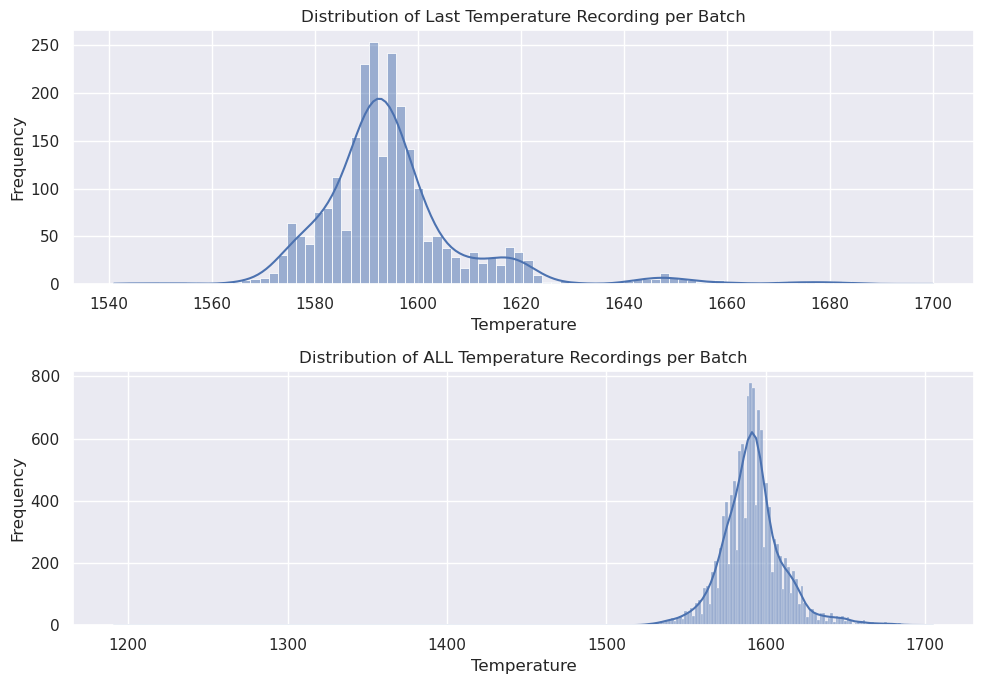

In [56]:
fig, axes = plt.subplots(2,1,figsize=(10,7))

sns.histplot(max_temp_per_key,x='temperature',discrete=False,kde=True,ax=axes[0])
axes[0].set_title("Distribution of Last Temperature Recording per Batch")
axes[0].set_xlabel("Temperature")
axes[0].set_ylabel("Frequency")

sns.histplot(data_temp_en,x='temperature',discrete=False,kde=True,ax=axes[1])
axes[1].set_title("Distribution of ALL Temperature Recordings per Batch")
axes[1].set_xlabel("Temperature")
axes[1].set_ylabel("Frequency")

plt.tight_layout()
plt.show()

In [57]:
print("Distribution of final temperature measurements only:\n",max_temp_per_key.loc[(max_temp_per_key['sampling_no'] != 1),'temperature'].describe())
print("Distribution of all temperature measurements, including the final ones:\n",data_temp_en.loc[(data_temp_en['sampling_no'] != 1),'temperature'].describe())
print("Distribution of all temperature measurements except the final ones:\n",data_temp_en.loc[(data_temp_en['sampling_no'] != 1) & (~data_temp_en.index.isin(max_temp_per_key.index)),'temperature'].describe())

Distribution of final temperature measurements only:
 count    2475.000000
mean     1595.336162
std        16.023153
min      1541.000000
25%      1587.000000
50%      1593.000000
75%      1599.000000
max      1700.000000
Name: temperature, dtype: float64
Distribution of all temperature measurements, including the final ones:
 count    9790.000000
mean     1592.908172
std        17.988920
min      1383.000000
25%      1583.000000
50%      1592.000000
75%      1600.000000
max      1705.000000
Name: temperature, dtype: float64
Distribution of all temperature measurements except the final ones:
 count    7315.000000
mean     1592.086671
std        18.536217
min      1383.000000
25%      1581.000000
50%      1591.000000
75%      1601.000000
max      1705.000000
Name: temperature, dtype: float64
